# Building Permits: Neighbourhood Clustering (K-Means)
Groups Vancouver's 22 neighbourhoods by their permit activity, to see which areas behave alike.
This is a descriptive analysis, separate from the classification models.

In [1]:
# Imports and Loading important Data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
SEED = 42

PROJECT_ROOT = Path("..")
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(PROJECT_ROOT / "data" / "clean" / "permits_clean.csv")
print(df.shape)

(47438, 14)


In [3]:
# Building one profile per neighbourhood
nb = df[df["area"] != "Unknown"]

profile = nb.groupby("area").agg(
    permits=("on_time", "size"),
    share_new_building=("type_of_work", lambda s: (s == "New Building").mean()),
    share_alteration=("type_of_work", lambda s: (s == "Addition / Alteration").mean()),
    median_value=("project_value", "median"),
    median_days=("elapsed_days", "median"),
    on_time_rate=("on_time", "mean"),
    lat=("lat", "mean"),
    lon=("lon", "mean"),
)
print(profile.shape)
profile.round(2)

(22, 8)


,permits,share_new_building,share_alteration,median_value,median_days,on_time_rate,lat,lon
area,,,,,,,,
Arbutus Ridge,1190,0.32,0.31,50000.0,103.5,0.43,49.25,-123.16
Downtown,6968,0.01,0.95,80000.0,36.0,0.83,49.28,-123.12
Dunbar-Southlands,2329,0.34,0.22,40000.0,122.0,0.37,49.24,-123.18
Fairview,2178,0.02,0.94,60000.0,42.0,0.77,49.26,-123.13
Grandview-Woodland,1686,0.17,0.52,40000.0,94.0,0.46,49.27,-123.07
Hastings-Sunrise,2835,0.34,0.25,40000.0,123.0,0.37,49.28,-123.04
Kensington-Cedar Cottage,3634,0.30,0.31,35000.0,117.0,0.39,49.25,-123.07
Kerrisdale,1192,0.31,0.30,45000.0,121.5,0.39,49.23,-123.16
Killarney,1550,0.33,0.35,40000.0,123.5,0.38,49.22,-123.04


#### The 379 “Unknown” permits are left out, since they don’t belong to a real area. elapsed_days is fine to use here, because this isn’t a classifier.

### Choosing the clustering features
Several profile measures are almost the same information: share of new buildings, share of alterations,
median days and on-time rate are all correlated at about 0.95 or more. Using all of them would count one idea
several times. We cluster on four features that each describe something different:
- **permits** – how busy the area is (log scale)
- **share_alteration** – what kind of work is done there
- **median_value** – typical project size (log scale)
- **on_time_rate** – how quickly permits are processed

All four are standardised so that no feature dominates because of its units.

In [4]:
# Selecting and Scaling the features
CLUSTER_FEATURES = ["permits", "share_alteration", "median_value", "on_time_rate"]

X = profile[CLUSTER_FEATURES].copy()
X["permits"] = np.log(X["permits"])
X["median_value"] = np.log1p(X["median_value"])

Z = StandardScaler().fit_transform(X)
print(Z.shape)

(22, 4)


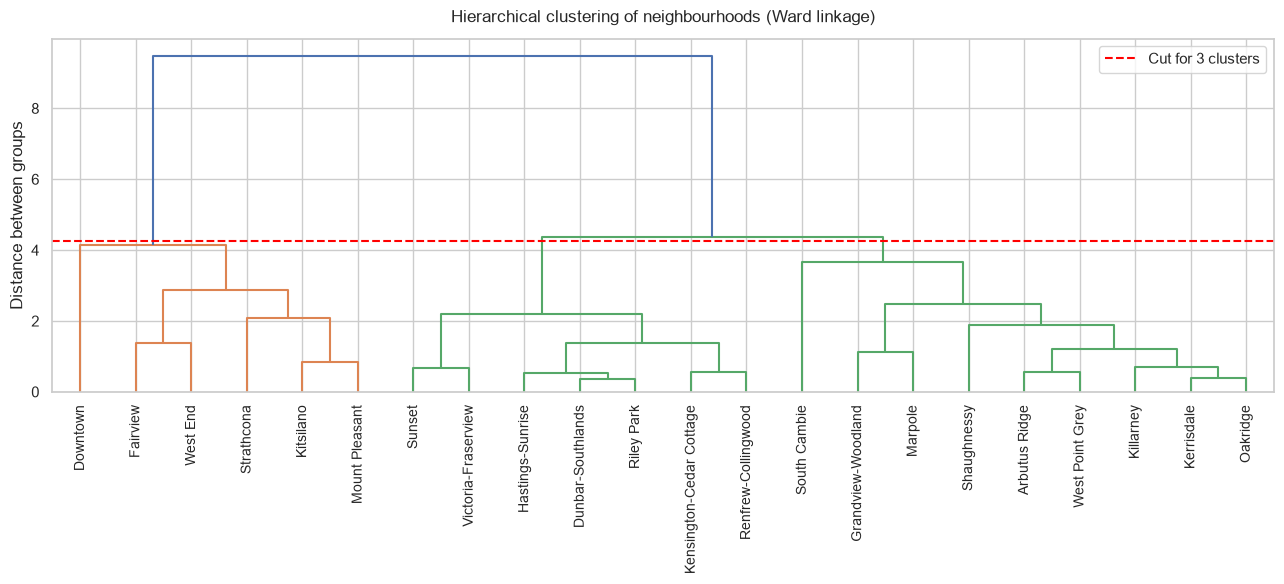

In [5]:
# Dendogram
L = linkage(Z, method="ward")
cut = (L[-2, 2] + L[-3, 2]) / 2      # height that splits the tree into 3 groups

fig, ax = plt.subplots(figsize=(13, 6))
dendrogram(L, labels=profile.index.tolist(), leaf_rotation=90, ax=ax)
ax.axhline(cut, color="red", linestyle="--", label="Cut for 3 clusters")
ax.set_title("Hierarchical clustering of neighbourhoods (Ward linkage)", pad=12)
ax.set_ylabel("Distance between groups")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "21_dendrogram.png", dpi=150)
plt.show()

#### The biggest split separates six central neighbourhoods (Downtown, West End, Fairview, Kitsilano, Mount Pleasant, Strathcona) from the rest. The next split divides the remaining residential areas into two groups.

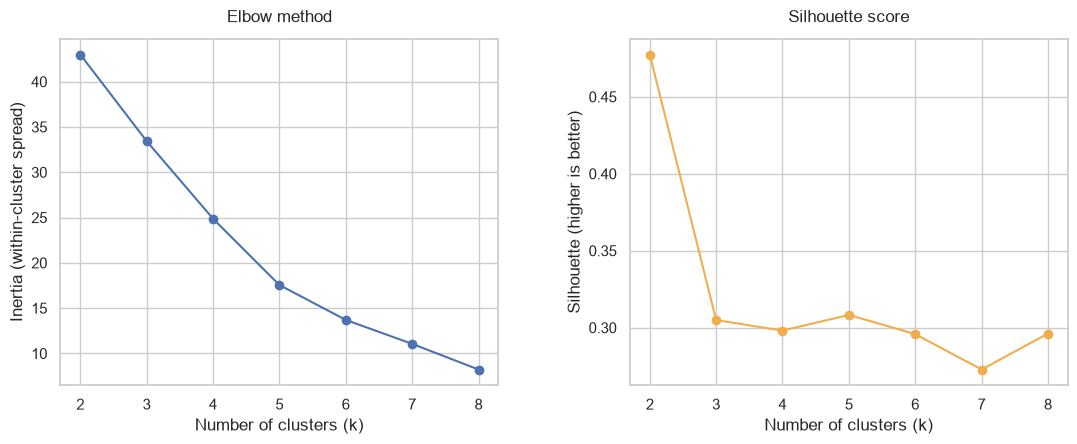

,inertia,silhouette
k,,
2,42.994,0.477
3,33.431,0.305
4,24.872,0.298
5,17.550,0.308
6,13.697,0.296
7,11.055,0.273
8,8.223,0.296


In [6]:
# elbow and silhouette
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
    rows.append((k, km.inertia_, silhouette_score(Z, km.labels_)))
k_scores = pd.DataFrame(rows, columns=["k", "inertia", "silhouette"]).set_index("k")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"wspace": 0.3})
ax[0].plot(k_scores.index, k_scores["inertia"], marker="o")
ax[0].set_title("Elbow method", pad=12)
ax[0].set_xlabel("Number of clusters (k)")
ax[0].set_ylabel("Inertia (within-cluster spread)")

ax[1].plot(k_scores.index, k_scores["silhouette"], marker="o", color="#f0ad4e")
ax[1].set_title("Silhouette score", pad=12)
ax[1].set_xlabel("Number of clusters (k)")
ax[1].set_ylabel("Silhouette (higher is better)")

plt.savefig(FIG_DIR / "22_elbow_silhouette.png", dpi=150, bbox_inches="tight")
plt.show()
k_scores.round(3)

### Choosing k = 3
- The silhouette score is highest at k = 2, but that split only separates the central neighbourhoods from all the others.
- The dendrogram's next natural split divides the residential neighbourhoods into two groups, giving k = 3.
- Although k = 5 scores little bit higher (0.308) but it splits off single neighbourhoods (e.g. Downtown alone), which does not describe groups of    similar areas.
- So, we choose k = 3 because the elbow curve shows no clear bend that would favour more clusters.

We use **k = 3** as the most informative grouping, accepting a moderate silhouette score.

In [7]:
# K-Means with k = 3, and the cluster profiles
K = 3
kmeans = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Z)
profile["cluster"] = kmeans.labels_

summary = profile.groupby("cluster").agg(
    neighbourhoods=("permits", "size"),
    total_permits=("permits", "sum"),
    share_new_building=("share_new_building", "mean"),
    share_alteration=("share_alteration", "mean"),
    median_value=("median_value", "mean"),
    median_days=("median_days", "mean"),
    on_time_rate=("on_time_rate", "mean"),
).round(2)
display(summary)

for c, g in profile.groupby("cluster"):
    print(f"Cluster {c}:", ", ".join(sorted(g.index)))

,neighbourhoods,total_permits,share_new_building,share_alteration,median_value,median_days,on_time_rate
cluster,,,,,,,
0,6,16835,0.06,0.84,60333.33,53.17,0.69
1,9,11753,0.29,0.35,42777.78,113.44,0.41
2,7,18471,0.35,0.26,41717.43,122.93,0.37


Cluster 0: Downtown, Fairview, Kitsilano, Mount Pleasant, Strathcona, West End
Cluster 1: Arbutus Ridge, Grandview-Woodland, Kerrisdale, Killarney, Marpole, Oakridge, Shaughnessy, South Cambie, West Point Grey
Cluster 2: Dunbar-Southlands, Hastings-Sunrise, Kensington-Cedar Cottage, Renfrew-Collingwood, Riley Park, Sunset, Victoria-Fraserview


### Interpretation
- Cluster 0: Central, commercial
- Cluster 1: Quieter residential
- Cluster 2: Busy residential


Variance explained by 2 components: [0.613 0.22 ]


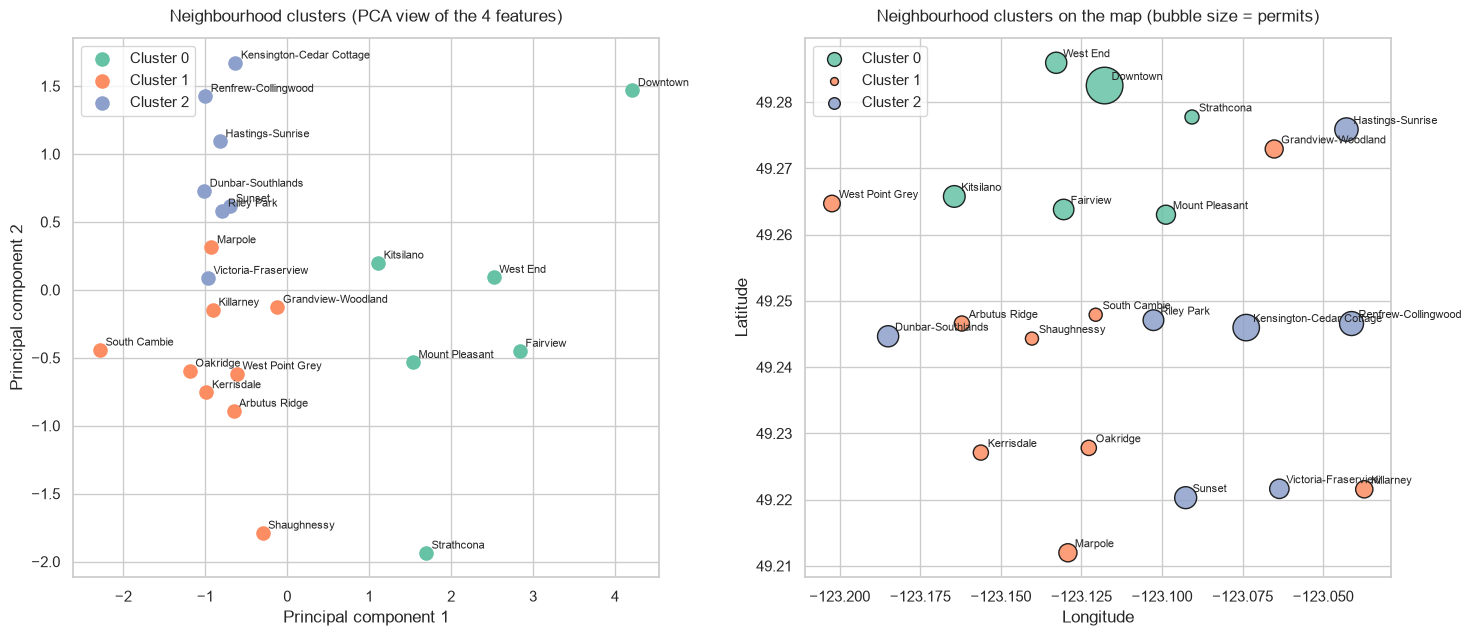

In [8]:
# Cluster in 2D and on the map
pca = PCA(n_components=2, random_state=SEED)
P = pca.fit_transform(Z)
print("Variance explained by 2 components:", pca.explained_variance_ratio_.round(3))

palette = sns.color_palette("Set2", K)
fig, ax = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={"wspace": 0.25})

for c in range(K):
    m = (profile["cluster"] == c).values
    ax[0].scatter(P[m, 0], P[m, 1], s=90, color=palette[c], label=f"Cluster {c}")
    ax[1].scatter(profile["lon"][m], profile["lat"][m], s=profile["permits"][m] / 10,
                  color=palette[c], alpha=0.85, edgecolor="black", label=f"Cluster {c}")

for i, area in enumerate(profile.index):
    ax[0].annotate(area, (P[i, 0], P[i, 1]), fontsize=8, xytext=(4, 3), textcoords="offset points")
    ax[1].annotate(area, (profile["lon"].iloc[i], profile["lat"].iloc[i]), fontsize=8,
                   xytext=(5, 4), textcoords="offset points")

ax[0].set_title("Neighbourhood clusters (PCA view of the 4 features)", pad=12)
ax[0].set_xlabel("Principal component 1")
ax[0].set_ylabel("Principal component 2")
ax[0].legend()

ax[1].set_title("Neighbourhood clusters on the map (bubble size = permits)", pad=12)
ax[1].set_xlabel("Longitude")
ax[1].set_ylabel("Latitude")
ax[1].legend(markerscale=0.5)

plt.savefig(FIG_DIR / "23_clusters_pca_map.png", dpi=150, bbox_inches="tight")
plt.show()

### The left panel is a 2D summary of the four features. PCA keeps 83% of their variation (61% + 22%), so it’s a fair picture. The right panel shows each neighbourhood at its average permit location. The central cluster sits around Downtown and the north, the busy residential cluster in the east and south, and the quieter one in the west and south-west.